# Practical Work 5 — Classification

## Classification Threshold Optimization

**Variant:** B

**Dataset:** Breast Cancer Wisconsin Diagnostic

**Model:** Logistic Regression

**Positive class:** Malignant (1)

**Negative class:** Benign (0)

In [1]:
import pandas as pd
import numpy as np
from sklearn.datasets import load_breast_cancer

# Load the dataset
dataset = load_breast_cancer(as_frame=True)

df = dataset.frame.copy()

# Save the dataset
data_path = "../data/breast_cancer.csv"
df.to_csv(data_path, index=False)

print("Dataset saved successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset saved successfully!
Dataset shape: (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)

print("Libraries imported successfully!")


Libraries imported successfully!


In [3]:
data_path = Path("../data/breast_cancer.csv")

df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)

display(df.head())

Dataset shape: (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         569 non-null

In [5]:
print(df.isnull().sum().sum())

0


## Feature Selection

The target variable is diagnosis.

The original dataset contains two classes:
- 0 — malignant
- 1 — benign

For this practical work, malignant cases are defined as the positive class (1), because false negative predictions are considered more costly.

The ID column is not used as a model feature.

X = df.drop(columns=["target"])

# Convert labels:
# 1 = malignant
# 0 = benign

y = (df["target"] == 0).astype(int)

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nClass distribution:")
print(y.value_counts())

print("\nClass names:")
print("1 = Malignant")
print("0 = Benign")

## Train-Test Split

The dataset is divided into training and testing sets.

Stratification is used to preserve the class proportions.

The test set is not used for model training or threshold selection.

In [8]:
X = df.drop(columns=["target"])
y = (df["target"] == 0).astype(int)
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train_full.shape)
print("Testing data:", X_test.shape)

Training data: (455, 30)
Testing data: (114, 30)


In [9]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.2,
    random_state=42,
    stratify=y_train_full
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)


Training: (364, 30)
Validation: (91, 30)
Testing: (114, 30)


## Model Training

Logistic Regression is used for binary classification.

StandardScaler is included in the Pipeline.

The model is fitted only on the training data.

In [10]:
model_pipeline = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=5000))
])

model_pipeline.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


## Probability Predictions

The predict_proba() method is used to obtain class probabilities instead of immediate binary predictions.

The probability of the positive class (malignant) is used for threshold selection.

In [11]:
# Find the position of positive class 1
positive_class_index = list(
    model_pipeline.named_steps["classifier"].classes_
).index(1)

# Probabilities on validation and test sets
val_probabilities = model_pipeline.predict_proba(X_val)[
    :, positive_class_index
]

test_probabilities = model_pipeline.predict_proba(X_test)[
    :, positive_class_index
]

print("First 10 probabilities:")
print(val_probabilities[:10])

First 10 probabilities:
[7.91370760e-02 9.38210889e-02 1.22177230e-04 9.98847915e-01
 9.99981229e-01 9.80287472e-01 4.23492587e-02 9.99357610e-01
 9.99922743e-01 3.81835893e-03]


## ROC Curve and ROC-AUC

The ROC curve shows the relationship between the True Positive Rate and False Positive Rate at different classification thresholds.

ROC-AUC measures the ability of the model to distinguish between the two classes.

A value closer to 1 indicates better class separation. A value around 0.5 indicates performance close to random ranking.

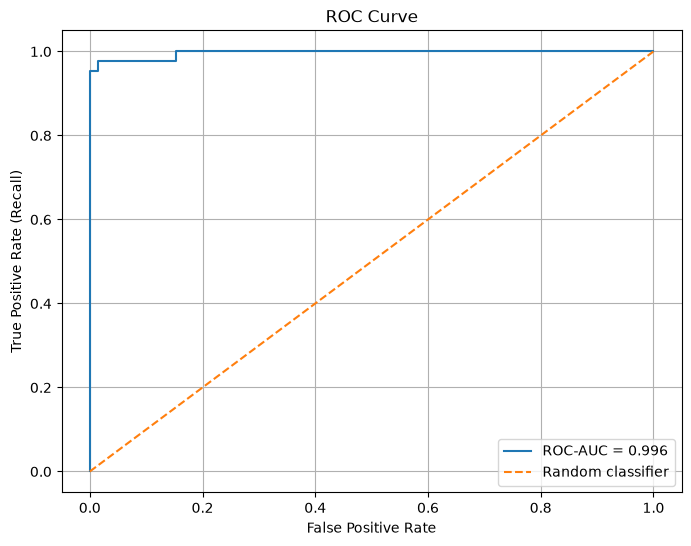

ROC-AUC: 0.996


In [12]:
fpr, tpr, roc_thresholds = roc_curve(
    y_test,
    test_probabilities
)

roc_auc = roc_auc_score(
    y_test,
    test_probabilities
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"ROC-AUC = {roc_auc:.3f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve")
plt.legend()
plt.grid()
plt.show()

print("ROC-AUC:", round(roc_auc, 3))

## Precision-Recall Curve

The Precision-Recall curve shows the relationship between precision and recall at different thresholds.

Recall is especially important in this task because false negative predictions are considered more costly.

Average Precision summarizes the Precision-Recall curve.

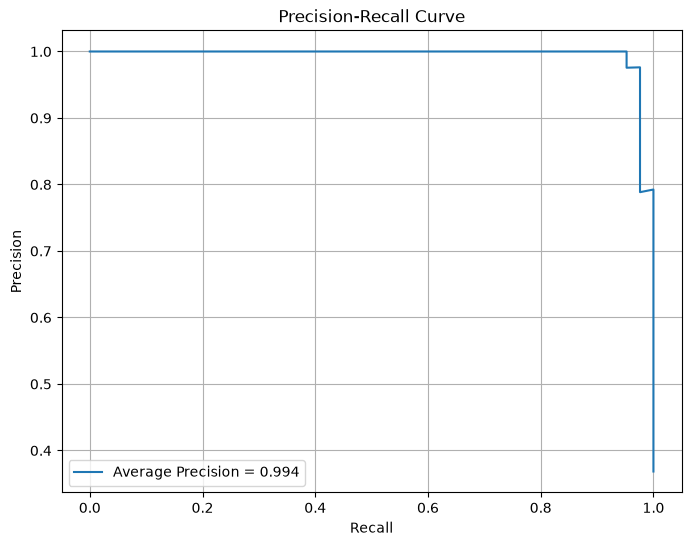

Average Precision: 0.994


In [13]:
precision_values, recall_values, pr_thresholds = precision_recall_curve(
    y_test,
    test_probabilities
)

pr_auc = average_precision_score(
    y_test,
    test_probabilities
)

plt.figure(figsize=(8, 6))

plt.plot(
    recall_values,
    precision_values,
    label=f"Average Precision = {pr_auc:.3f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.grid()
plt.show()

print("Average Precision:", round(pr_auc, 3))

## Classification Threshold Selection

A false negative is more costly than a false positive in this example.

The threshold is selected by minimizing the total classification error cost on the validation set.

The costs used in this demonstration are:
- False Positive Cost = 1
- False Negative Cost = 5

In [14]:
# Replace these values with the costs given by the teacher.
FP_COST = 1
FN_COST = 5

thresholds = np.arange(0.01, 1.00, 0.01)

threshold_results = []

for threshold in thresholds:
    val_predictions = (
        val_probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        val_predictions,
        labels=[0, 1]
    ).ravel()

    total_cost = FP_COST * fp + FN_COST * fn

    threshold_results.append({
        "Threshold": threshold,
        "FP": fp,
        "FN": fn,
        "Total Cost": total_cost
    })

threshold_table = pd.DataFrame(threshold_results)

best_row = threshold_table.loc[
    threshold_table["Total Cost"].idxmin()
]

best_threshold = best_row["Threshold"]

display(threshold_table.sort_values(
    "Total Cost"
).head(10))

print("Selected threshold:", round(best_threshold, 2))
print("Minimum validation cost:", best_row["Total Cost"])

,Threshold,FP,FN,Total Cost
63,0.64,0,1,5
78,0.79,0,1,5
77,0.78,0,1,5
92,0.93,0,1,5
91,0.92,0,1,5
90,0.91,0,1,5
89,0.90,0,1,5
88,0.89,0,1,5
87,0.88,0,1,5
86,0.87,0,1,5


Selected threshold: 0.64
Minimum validation cost: 5.0


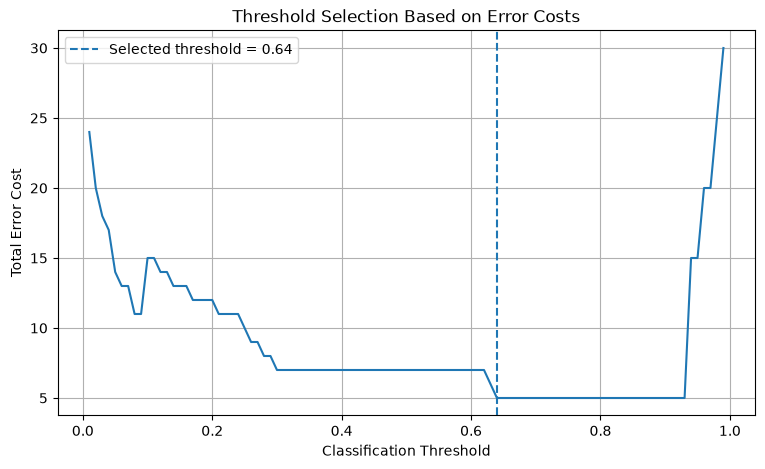

In [15]:
plt.figure(figsize=(9, 5))

plt.plot(
    threshold_table["Threshold"],
    threshold_table["Total Cost"]
)

plt.axvline(
    best_threshold,
    linestyle="--",
    label=f"Selected threshold = {best_threshold:.2f}"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Total Error Cost")
plt.title("Threshold Selection Based on Error Costs")
plt.legend()
plt.grid()
plt.show()

## Comparison of Classification Thresholds

Two classification thresholds are compared:

- Default threshold: 0.5
- Cost-sensitive threshold: selected using validation data

Both thresholds are evaluated on the same test set.

In [16]:
default_threshold = 0.5

test_predictions_default = (
    test_probabilities >= default_threshold
).astype(int)

test_predictions_optimized = (
    test_probabilities >= best_threshold
).astype(int)

In [17]:
def calculate_metrics(y_true, y_pred, model_name):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0)
    }


default_metrics = calculate_metrics(
    y_test,
    test_predictions_default,
    "Threshold 0.5"
)

optimized_metrics = calculate_metrics(
    y_test,
    test_predictions_optimized,
    f"Threshold {best_threshold:.2f}"
)

comparison = pd.DataFrame([
    default_metrics,
    optimized_metrics
])

display(comparison.round(3))

,Model,Accuracy,Precision,Recall,F1
0,Threshold 0.5,0.982,0.976,0.976,0.976
1,Threshold 0.64,0.982,1.000,0.952,0.976


## Confusion Matrix

The confusion matrices show the number of true positive, true negative, false positive and false negative predictions.

The positive class is malignant (1).

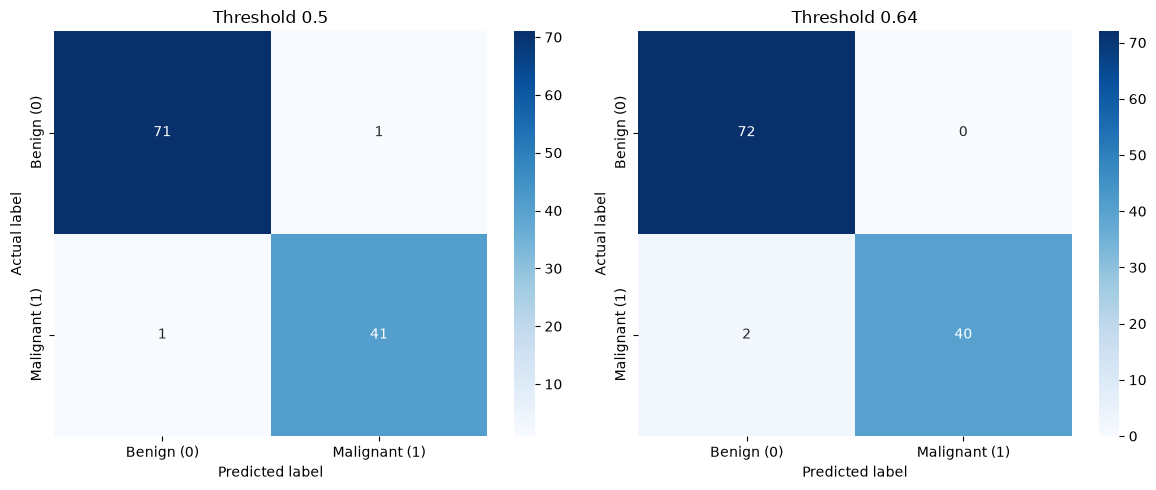

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

predictions_list = [
    (test_predictions_default, "Threshold 0.5"),
    (test_predictions_optimized, f"Threshold {best_threshold:.2f}")
]

for ax, (predictions, title) in zip(axes, predictions_list):
    cm = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax,
        xticklabels=["Benign (0)", "Malignant (1)"],
        yticklabels=["Benign (0)", "Malignant (1)"]
    )

    ax.set_title(title)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")

plt.tight_layout()
plt.show()

## Conclusion

In this practical work, a Logistic Regression classification model was trained using the Breast Cancer Wisconsin Diagnostic dataset.

The model generated class probabilities using predict_proba().

ROC and Precision-Recall curves were constructed. ROC-AUC and Average Precision were calculated to evaluate the model's ability to distinguish between the classes.

The default classification threshold of 0.5 was compared with a cost-sensitive threshold selected using the validation set.

False negative errors were assigned a higher cost than false positive errors.

The selected threshold was INSERT THRESHOLD.

The comparison showed that the optimized threshold INCREASED / DECREASED recall and INCREASED / DECREASED precision compared with the default threshold.

The final threshold was selected by minimizing the total cost of false positive and false negative errors on the validation set.

The final evaluation was performed on an independent test set.